In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, f1_score, classification_report, confusion_matrix

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor, RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVR, SVC
from sklearn.dummy import DummyRegressor, DummyClassifier

sns.set_theme(style='whitegrid')
np.random.seed(42)

In [2]:
df = pd.read_csv(r"D:\tasks\Apartments Prices Dataset(Target column price).csv")
df.head()

,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [3]:
df.shape

(5578, 11)

In [4]:
df.columns

Index(['price', 'area_sqm', 'rooms', 'bathrooms', 'floor_level', 'year_built',
       'seller_type', 'view', 'price_per_sqm', 'payment_method',
       'finishing_type'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5578 entries, 0 to 5577
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   price           5572 non-null   str  
 1   area_sqm        5545 non-null   str  
 2   rooms           5550 non-null   str  
 3   bathrooms       5480 non-null   str  
 4   floor_level     5578 non-null   str  
 5   year_built      5578 non-null   int64
 6   seller_type     5387 non-null   str  
 7   view            5556 non-null   str  
 8   price_per_sqm   5534 non-null   str  
 9   payment_method  5566 non-null   str  
 10  finishing_type  5578 non-null   str  
dtypes: int64(1), str(10)
memory usage: 479.5 KB


In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
price,5572,1321,"6,500,000 EGP",94,NaN,NaN,NaN,NaN,NaN,NaN,NaN
area_sqm,5545,251,140 m²,173,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rooms,5550,11,3 rooms,3084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bathrooms,5480,11,1 bathroom,1938,NaN,NaN,NaN,NaN,NaN,NaN,NaN
floor_level,5578,22,1,1831,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_built,5578.0,NaN,NaN,NaN,2022.327178,8.431095,1915.0,2023.0,2025.0,2026.0,2037.0
seller_type,5387,7,Broker,4719,NaN,NaN,NaN,NaN,NaN,NaN,NaN
view,5556,13,Main Street,1719,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_per_sqm,5534,2123,"50,000 EGP/M²",103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,5566,3,Cash,2568,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.isnull().sum().sort_values(ascending=False)

seller_type       191
bathrooms          98
price_per_sqm      44
area_sqm           33
rooms              28
view               22
payment_method     12
price               6
floor_level         0
year_built          0
finishing_type      0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(1298)

In [9]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

(4280, 11)

In [10]:
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].astype('string').str.strip()

df.head()

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_20232\3446243755.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


,price,area_sqm,rooms,bathrooms,floor_level,year_built,seller_type,view,price_per_sqm,payment_method,finishing_type
0,"2,163,000 EGP",120 m²,2 rooms,3 bathroom,3,2025,Developer,Main Street,"18,025 EGP/M²",Installments,Semi Finished
1,"3,250,000 EGP",162 m²,3 rooms,2 bathroom,6,2024,Developer,Main Street,"20,062 EGP/M²",Cash or Installments,Semi Finished
2,"2,650,000 EGP",122 m²,3 rooms,1 bathroom,4,2024,Developer,Main Street,"21,721 EGP/M²",Cash or Installments,Semi Finished
3,"12,720,000 EGP",212 m²,4 rooms,3 bathroom,13,2027,Broker,Club,"60,000 EGP/M²",Cash or Installments,Extra Super Lux
4,"5,898,000 EGP",135 m²,2 rooms,1 bathroom,6,2025,Developer,Lake,"43,689 EGP/M²",Cash or Installments,Super Lux


In [11]:
df['price'] = pd.to_numeric(df['price'].astype('string').str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
df['area_sqm'] = pd.to_numeric(df['area_sqm'].astype('string').str.replace(r'[^0-9.]', '', regex=True), errors='coerce')
df['rooms'] = pd.to_numeric(df['rooms'].astype('string').str.extract(r'(\d+)', expand=False), errors='coerce')
df['bathrooms'] = pd.to_numeric(df['bathrooms'].astype('string').str.extract(r'(\d+)', expand=False), errors='coerce')
df['floor_level'] = df['floor_level'].replace({'Ground': '0'}).astype('string').str.extract(r'(\d+)', expand=False)
df['floor_level'] = pd.to_numeric(df['floor_level'], errors='coerce')
df['year_built'] = pd.to_numeric(df['year_built'], errors='coerce')
df.isnull().sum()

price               6
area_sqm           33
rooms              28
bathrooms          97
floor_level         0
year_built          0
seller_type       172
view               21
price_per_sqm      34
payment_method     12
finishing_type      0
dtype: int64

In [12]:
for col in ['rooms', 'bathrooms']:
    df.loc[(df[col] <= 0) | (df[col] > 20), col] = np.nan
df.loc[df['area_sqm'] <= 0, 'area_sqm'] = np.nan
df.loc[df['floor_level'] < 0, 'floor_level'] = np.nan
df.loc[df['year_built'] < 1900, 'year_built'] = np.nan
df.dropna(subset=['price'], inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

(4274, 11)

In [13]:
df.isnull().sum().sort_values(ascending=False)

seller_type       172
bathrooms          93
price_per_sqm      33
area_sqm           27
rooms              26
view               21
payment_method     11
price               0
floor_level         0
year_built          0
finishing_type      0
dtype: int64

In [14]:
for col in df.select_dtypes(include='string').columns:
    df[col] = df[col].astype(object)
    df[col] = df[col].where(pd.notna(df[col]), np.nan)

df.isnull().sum()

price               0
area_sqm           27
rooms              26
bathrooms          93
floor_level         0
year_built          0
seller_type       172
view               21
price_per_sqm      33
payment_method     11
finishing_type      0
dtype: int64

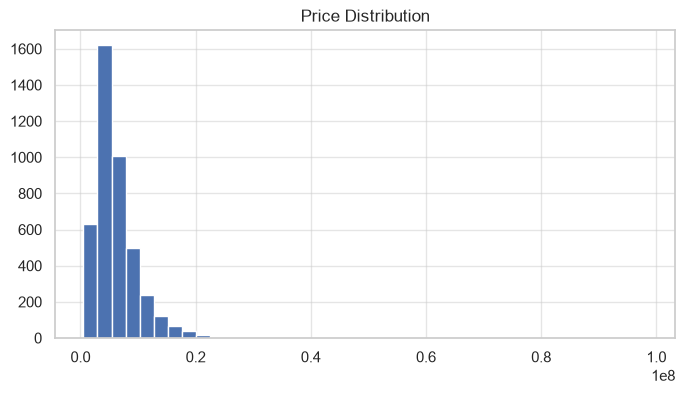

In [15]:
plt.figure(figsize=(8, 4))
plt.hist(df['price'], bins=40)
plt.title('Price Distribution')
plt.show()

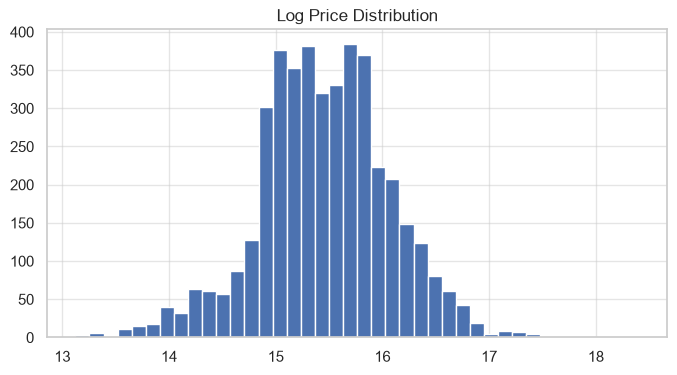

In [16]:
plt.figure(figsize=(8, 4))
plt.hist(np.log1p(df['price']), bins=40)
plt.title('Log Price Distribution')
plt.show()

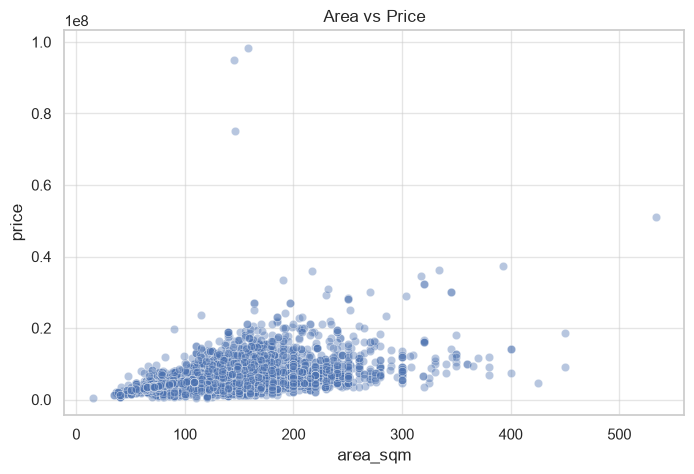

In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='area_sqm', y='price', alpha=0.4)
plt.title('Area vs Price')
plt.show()

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_20232\899964266.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df['price'], vert=False)


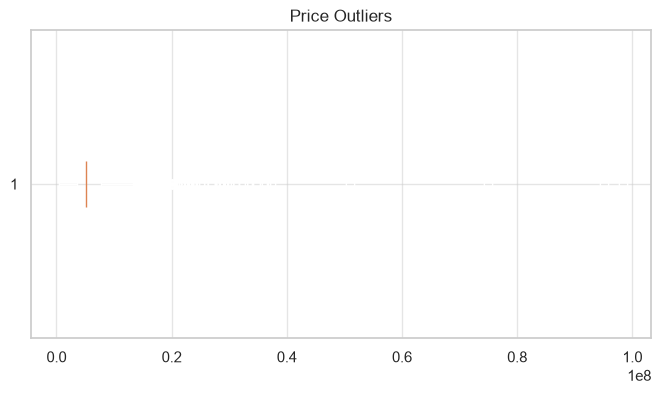

In [18]:
plt.figure(figsize=(8, 4))
plt.boxplot(df['price'], vert=False)
plt.title('Price Outliers')
plt.show()

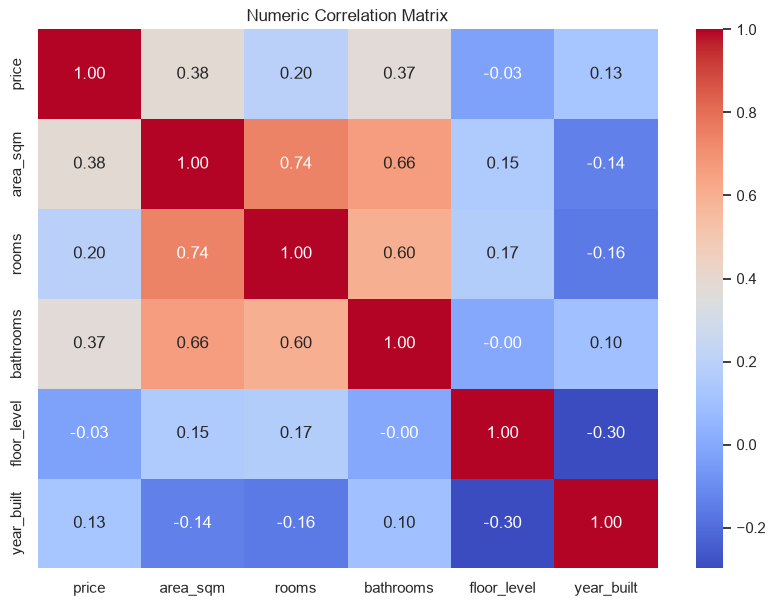

In [19]:
numeric_cols = df.select_dtypes(include=np.number).columns
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Numeric Correlation Matrix')
plt.show()

In [20]:
for col in ['seller_type', 'view', 'payment_method', 'finishing_type']:
    print('\n', col)
    print(df[col].value_counts(dropna=False))


 seller_type
seller_type
Broker                  3564
Developer                333
Private Owner            176
NaN                      172
Compound Developer        20
Cash                       5
Cash or Installments       3
Installments               1
Name: count, dtype: int64

 view
view
Main Street    1363
Garden         1092
Side Street     531
Other           419
Pool            395
Corner          128
Sea View        114
Back             83
Lake             49
Plaza            47
NaN              21
Club             15
Nile View        12
Golf Course       5
Name: count, dtype: int64

 payment_method
payment_method
Cash                    2163
Installments            1108
Cash or Installments     992
NaN                       11
Name: count, dtype: int64

 finishing_type
finishing_type
Super Lux          1505
Semi Finished      1141
Extra Super Lux    1076
Without Finish      403
Lux                 149
Name: count, dtype: int64


In [21]:
X = df.drop(columns=['price', 'price_per_sqm'], errors='ignore')
y = df['price'].astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
X_train.shape, X_test.shape

((3419, 9), (855, 9))

In [22]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
numeric_features, categorical_features

(['area_sqm', 'rooms', 'bathrooms', 'floor_level', 'year_built'],
 ['seller_type', 'view', 'payment_method', 'finishing_type'])

In [23]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

In [24]:
reg_models = {
    'Dummy': DummyRegressor(strategy='median'),
    'LinearRegression': LinearRegression(),
    'Ridge': Ridge(alpha=10),
    'Lasso': Lasso(alpha=1000, max_iter=10000),
    'ElasticNet': ElasticNet(alpha=0.1, max_iter=10000),
    'KNN': KNeighborsRegressor(n_neighbors=10),
    'DecisionTree': DecisionTreeRegressor(random_state=42),
    'RandomForest': RandomForestRegressor(n_estimators=150, random_state=42, n_jobs=-1),
    'ExtraTrees': ExtraTreesRegressor(n_estimators=150, random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingRegressor(random_state=42),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

In [25]:
reg_results = []

for name, model in reg_models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='neg_mean_absolute_error', n_jobs=1, error_score='raise')
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    reg_results.append({
        'Model': name,
        'CV_MAE': -cv_scores.mean(),
        'Test_MAE': mean_absolute_error(y_test, pred),
        'Test_RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'Test_R2': r2_score(y_test, pred)
    })

reg_results_df = pd.DataFrame(reg_results).sort_values('CV_MAE')
reg_results_df

,Model,CV_MAE,Test_MAE,Test_RMSE,Test_R2
7,RandomForest,1.841729e+06,1.881048e+06,4.327094e+06,0.265942
8,ExtraTrees,1.857835e+06,1.982269e+06,4.737706e+06,0.120018
10,HistGradientBoosting,1.969084e+06,1.906470e+06,3.983494e+06,0.377892
9,GradientBoosting,2.032725e+06,2.102179e+06,4.218788e+06,0.302229
5,KNN,2.063542e+06,2.074290e+06,4.375989e+06,0.249259
2,Ridge,2.260323e+06,2.332475e+06,4.413262e+06,0.236416
3,Lasso,2.262748e+06,2.334749e+06,4.412931e+06,0.236530
4,ElasticNet,2.265329e+06,2.346607e+06,4.437672e+06,0.227946
1,LinearRegression,2.265384e+06,2.337195e+06,4.413653e+06,0.236281
6,DecisionTree,2.392845e+06,2.472418e+06,5.925724e+06,-0.376640


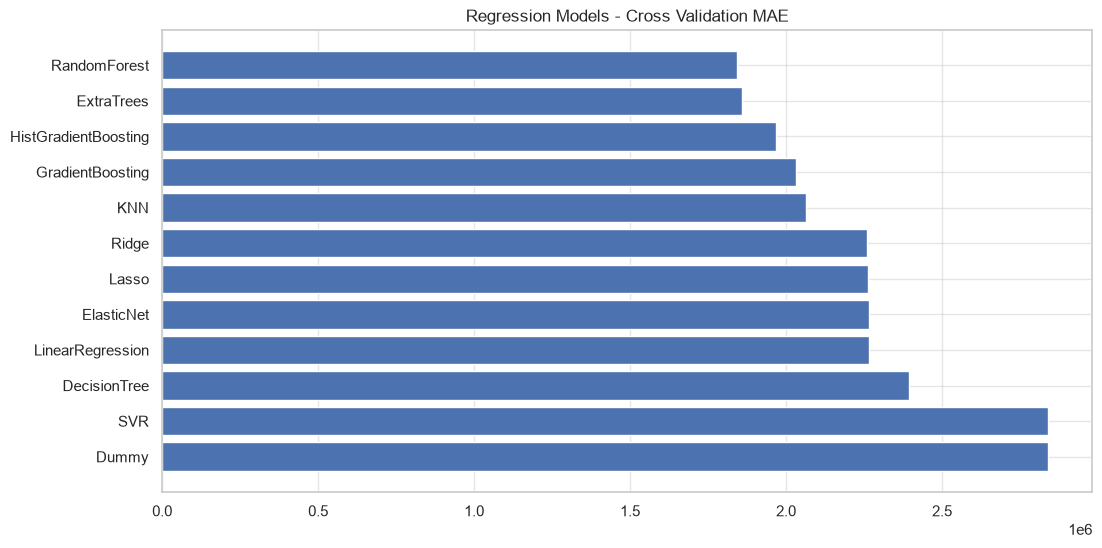

In [26]:
plt.figure(figsize=(12, 6))
plt.barh(reg_results_df['Model'], reg_results_df['CV_MAE'])
plt.gca().invert_yaxis()
plt.title('Regression Models - Cross Validation MAE')
plt.show()

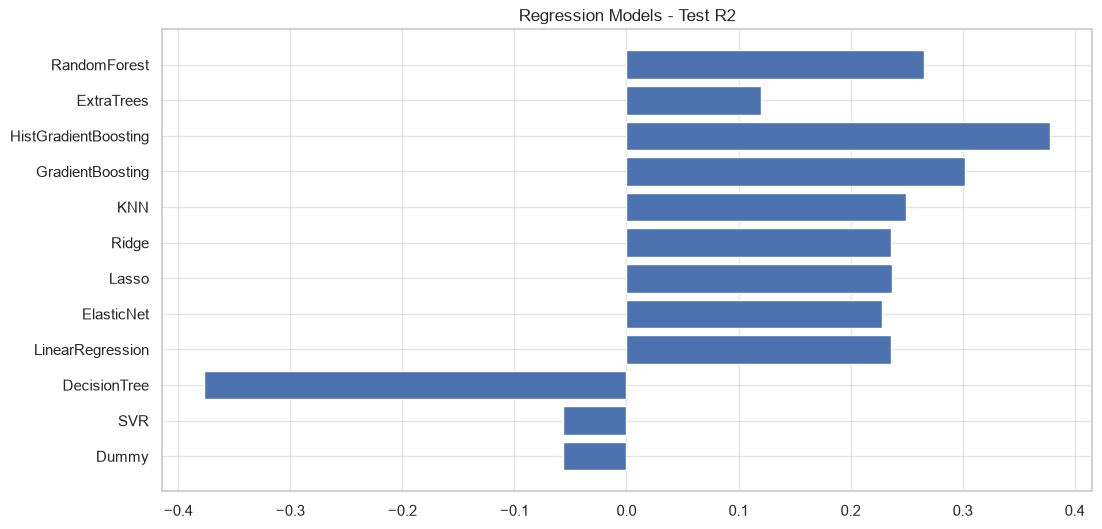

In [27]:
plt.figure(figsize=(12, 6))
plt.barh(reg_results_df['Model'], reg_results_df['Test_R2'])
plt.gca().invert_yaxis()
plt.title('Regression Models - Test R2')
plt.show()

In [28]:
best_reg_name = reg_results_df.iloc[0]['Model']
best_reg_model = reg_models[best_reg_name]
best_reg_pipe = Pipeline([('prep', preprocessor), ('model', best_reg_model)])
best_reg_pipe.fit(X_train, y_train)
best_reg_pred = best_reg_pipe.predict(X_test)
best_reg_name, mean_absolute_error(y_test, best_reg_pred), np.sqrt(mean_squared_error(y_test, best_reg_pred)), r2_score(y_test, best_reg_pred)

('RandomForest',
 1881048.280253965,
 np.float64(4327094.3850395745),
 0.2659421567240928)

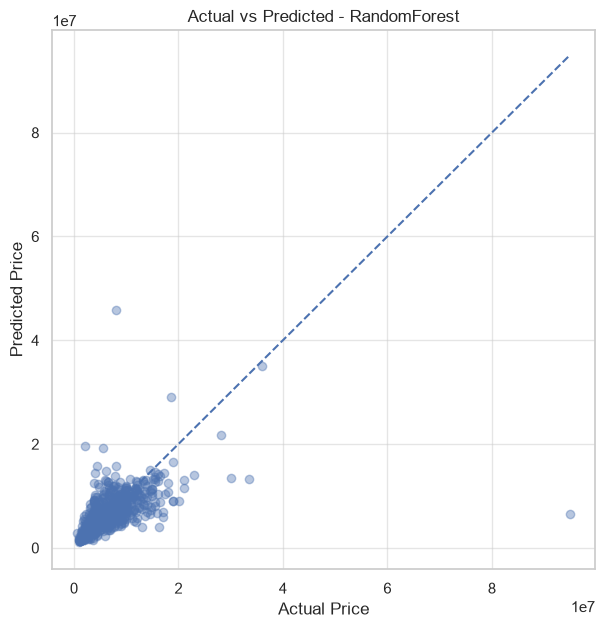

In [29]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, best_reg_pred, alpha=0.4)
lims = [min(y_test.min(), best_reg_pred.min()), max(y_test.max(), best_reg_pred.max())]
plt.plot(lims, lims, '--')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.title(f'Actual vs Predicted - {best_reg_name}')
plt.show()

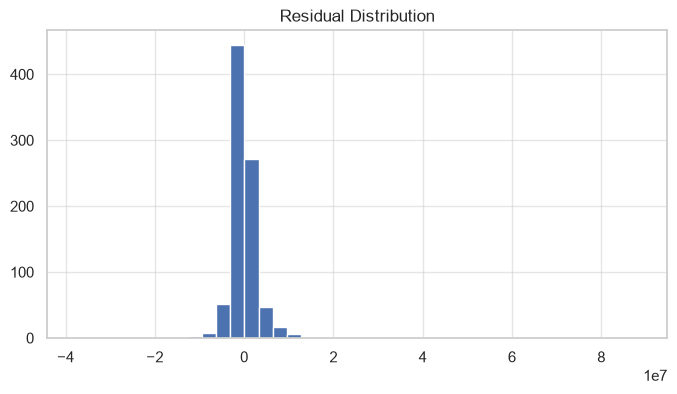

In [30]:
residuals = y_test - best_reg_pred
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=40)
plt.title('Residual Distribution')
plt.show()

In [31]:
df_cls = df.copy()
df_cls['price_category'] = pd.qcut(df_cls['price'], q=3, labels=['Low', 'Medium', 'High'])
df_cls['price_category'].value_counts()

price_category
Low       1426
Medium    1424
High      1424
Name: count, dtype: int64

In [32]:
X_cls = df_cls.drop(columns=['price', 'price_per_sqm', 'price_category'], errors='ignore')
y_cls = df_cls['price_category']
X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls
)
X_cls_train.shape, X_cls_test.shape

((3419, 9), (855, 9))

In [33]:
cls_num_features = X_cls_train.select_dtypes(include=np.number).columns.tolist()
cls_cat_features = X_cls_train.select_dtypes(exclude=np.number).columns.tolist()

cls_numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cls_categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

cls_preprocessor = ColumnTransformer([
    ('num', cls_numeric_pipeline, cls_num_features),
    ('cat', cls_categorical_pipeline, cls_cat_features)
])

In [34]:
cls_models = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'LogisticRegression': LogisticRegression(max_iter=2000),
    'KNN': KNeighborsClassifier(n_neighbors=10),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    'ExtraTrees': ExtraTreesClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    'GradientBoosting': GradientBoostingClassifier(random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(random_state=42),
    'SVC': SVC()
}

In [35]:
cls_results = []

for name, model in cls_models.items():
    pipe = Pipeline([('prep', cls_preprocessor), ('model', model)])
    cv_scores = cross_val_score(pipe, X_cls_train, y_cls_train, cv=5, scoring='f1_macro', n_jobs=1, error_score='raise')
    pipe.fit(X_cls_train, y_cls_train)
    pred = pipe.predict(X_cls_test)
    cls_results.append({
        'Model': name,
        'CV_F1': cv_scores.mean(),
        'Test_Accuracy': accuracy_score(y_cls_test, pred),
        'Test_F1_Macro': f1_score(y_cls_test, pred, average='macro')
    })

cls_results_df = pd.DataFrame(cls_results).sort_values('CV_F1', ascending=False)
cls_results_df

,Model,CV_F1,Test_Accuracy,Test_F1_Macro
7,HistGradientBoosting,0.694415,0.732164,0.731383
4,RandomForest,0.690734,0.721637,0.719924
5,ExtraTrees,0.664870,0.697076,0.696040
6,GradientBoosting,0.658735,0.680702,0.680347
8,SVC,0.640030,0.674854,0.674980
2,KNN,0.614351,0.656140,0.654413
3,DecisionTree,0.610407,0.651462,0.650083
1,LogisticRegression,0.592554,0.608187,0.604910
0,Dummy,0.166813,0.333333,0.166667


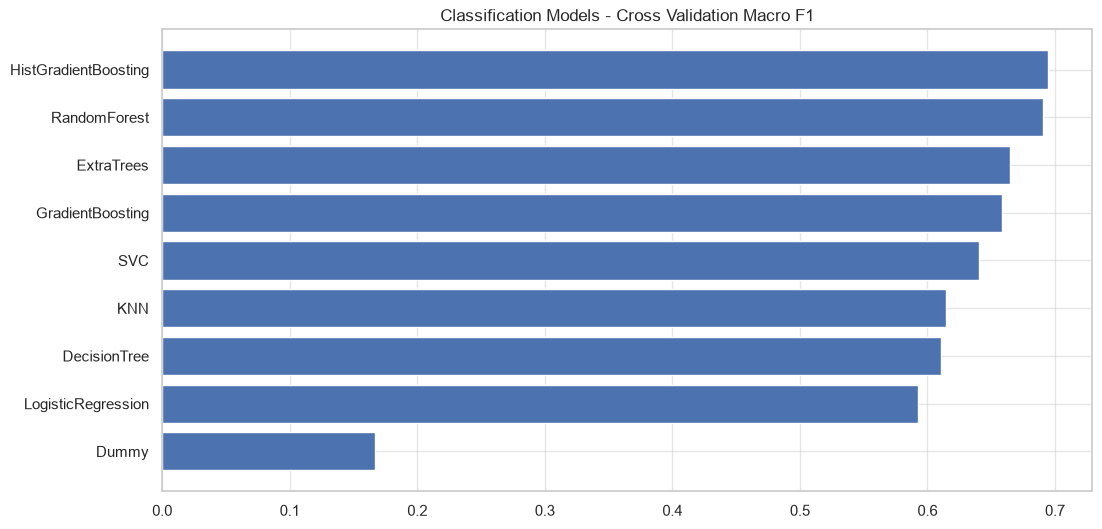

In [36]:
plt.figure(figsize=(12, 6))
plt.barh(cls_results_df['Model'], cls_results_df['CV_F1'])
plt.gca().invert_yaxis()
plt.title('Classification Models - Cross Validation Macro F1')
plt.show()

In [37]:
best_cls_name = cls_results_df.iloc[0]['Model']
best_cls_model = cls_models[best_cls_name]
best_cls_pipe = Pipeline([('prep', cls_preprocessor), ('model', best_cls_model)])
best_cls_pipe.fit(X_cls_train, y_cls_train)
best_cls_pred = best_cls_pipe.predict(X_cls_test)
print(best_cls_name)
print(classification_report(y_cls_test, best_cls_pred))

HistGradientBoosting
              precision    recall  f1-score   support

        High       0.74      0.78      0.76       285
         Low       0.80      0.80      0.80       285
      Medium       0.65      0.62      0.63       285

    accuracy                           0.73       855
   macro avg       0.73      0.73      0.73       855
weighted avg       0.73      0.73      0.73       855



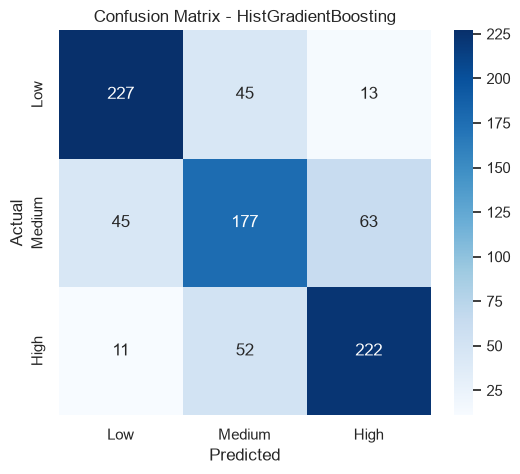

In [38]:
cm = confusion_matrix(y_cls_test, best_cls_pred, labels=['Low', 'Medium', 'High'])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Low', 'Medium', 'High'], yticklabels=['Low', 'Medium', 'High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title(f'Confusion Matrix - {best_cls_name}')
plt.show()

In [39]:
reg_results_df

,Model,CV_MAE,Test_MAE,Test_RMSE,Test_R2
7,RandomForest,1.841729e+06,1.881048e+06,4.327094e+06,0.265942
8,ExtraTrees,1.857835e+06,1.982269e+06,4.737706e+06,0.120018
10,HistGradientBoosting,1.969084e+06,1.906470e+06,3.983494e+06,0.377892
9,GradientBoosting,2.032725e+06,2.102179e+06,4.218788e+06,0.302229
5,KNN,2.063542e+06,2.074290e+06,4.375989e+06,0.249259
2,Ridge,2.260323e+06,2.332475e+06,4.413262e+06,0.236416
3,Lasso,2.262748e+06,2.334749e+06,4.412931e+06,0.236530
4,ElasticNet,2.265329e+06,2.346607e+06,4.437672e+06,0.227946
1,LinearRegression,2.265384e+06,2.337195e+06,4.413653e+06,0.236281
6,DecisionTree,2.392845e+06,2.472418e+06,5.925724e+06,-0.376640


In [40]:
cls_results_df

,Model,CV_F1,Test_Accuracy,Test_F1_Macro
7,HistGradientBoosting,0.694415,0.732164,0.731383
4,RandomForest,0.690734,0.721637,0.719924
5,ExtraTrees,0.664870,0.697076,0.696040
6,GradientBoosting,0.658735,0.680702,0.680347
8,SVC,0.640030,0.674854,0.674980
2,KNN,0.614351,0.656140,0.654413
3,DecisionTree,0.610407,0.651462,0.650083
1,LogisticRegression,0.592554,0.608187,0.604910
0,Dummy,0.166813,0.333333,0.166667
